Generate reproducible nonlinear data between 0 and 20, with 80 data points. Generate random noise and add realistic variation to the output data. Use pipeline model to calculate the training and testing MSE for degrees 1, 2, and 10. Analyse the bias and variance trade-offs. Plot the fitted models. 

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline

In [69]:
np.random.seed(42)
X = np.linspace(0, 20, 80)
y = 1 + 1.15 ** X + np.random.normal(0, 1, 80)
data = pd.DataFrame({
    "X": X,
    "y": y
})


In [70]:
X = X.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [72]:
degrees = [2, 3, 10]


Polynomial Degree: 2
Training MSE: 0.8521165632152442
Testing MSE: 0.7610352866424787

Polynomial Degree: 3
Training MSE: 0.8506889889710465
Testing MSE: 0.7439025055987

Polynomial Degree: 10
Training MSE: 0.7456548361462043
Testing MSE: 1.2418013621753003


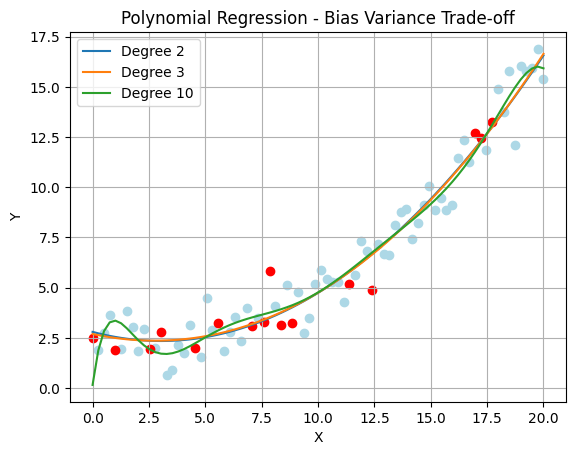

In [77]:
plt.scatter(X_train, y_train, c="lightblue")
plt.scatter(X_test, y_test, c="red")

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        StandardScaler(),
        LinearRegression()
    )
    
    model.fit(X_train, y_train)
    
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)

    print("\nPolynomial Degree:", degree)
    print("Training MSE:", train_mse)
    print("Testing MSE:", test_mse)
    
    X_plot = np.linspace(0, 20, 80).reshape(-1, 1)
    y_plot = model.predict(X_plot)

    plt.plot(X_plot, y_plot, label=f'Degree {degree}')
    
    
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Polynomial Regression - Bias Variance Trade-off")
plt.legend()
plt.grid()
plt.show()